In [1]:
import pandas as pd
import matplotlib.pyplot as plt

interval = pd.read_csv("../data/raw/interval_15min.csv", parse_dates=["timestamp"])  # academic + lab
monthly = pd.read_csv("../data/raw/monthly_totals.csv")                              # all buildings
interval.head()

,timestamp,building,building_type,temperature,kWh_consumed
0,2026-06-01 00:00:00,B3_Academic,academic,26.2,6.410
1,2026-06-01 00:15:00,B3_Academic,academic,23.9,7.082
2,2026-06-01 00:30:00,B3_Academic,academic,26.4,6.325
3,2026-06-01 00:45:00,B3_Academic,academic,26.4,7.204
4,2026-06-01 01:00:00,B3_Academic,academic,21.9,7.554


# 01 · Baseline exploration
Loads the synthetic campus dataset, resamples it, and plots the **4 PM – 8 PM evening demand spike**.

Metering differs by building type:
- **Academic blocks and labs** → 15-minute smart-meter readings (`interval_15min.csv`)
- **Hostels and libraries** → monthly bill only (`monthly_totals.csv`)

Run `python src/generate_data.py` first if `data/raw/` is empty.

## Data coverage
15-min buildings have short sensor dropouts; hostels and libraries have no sub-monthly data at all.

In [2]:
display(interval.groupby("building")["kWh_consumed"].apply(lambda s: s.isna().mean()).rename("missing_frac").round(4))
monthly.pivot(index=["building", "building_type"], columns="month", values="monthly_kWh")

building
B3_Academic    0.0063
B5_Lab         0.0104
Name: missing_frac, dtype: float64

,month,2026-06,2026-07,2026-08
building,building_type,,,
B1_Hostel_A,hostel,43886.0,45526.7,45014.4
B2_Hostel_B,hostel,39647.4,40970.1,40504.9
B3_Academic,academic,30022.7,31136.1,30723.0
B4_Library,library,27633.3,28592.8,28219.8
B5_Lab,lab,42636.7,44092.1,43652.4


## Resampling
15-min → daily totals for the metered buildings; monthly totals for every building.

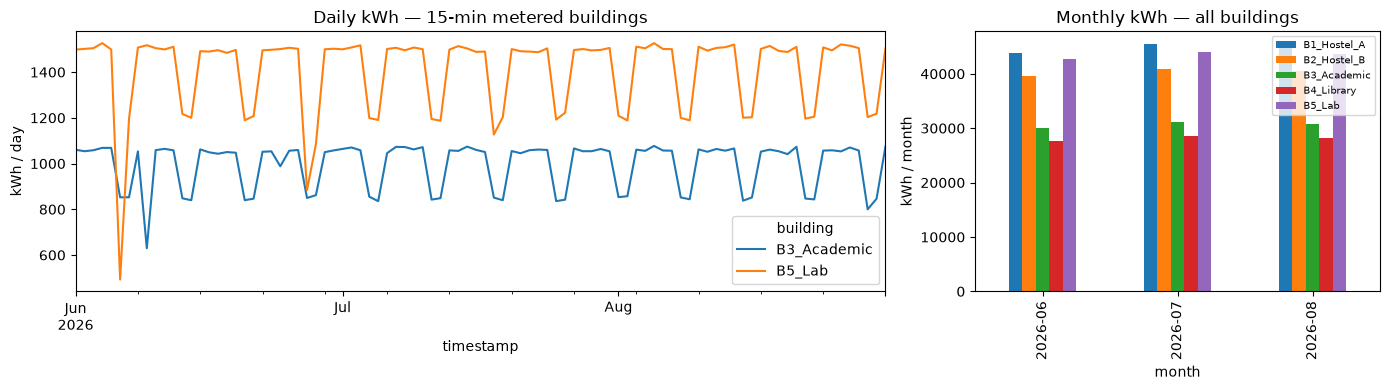

In [3]:
wide = interval.pivot(index="timestamp", columns="building", values="kWh_consumed")

hourly = wide.resample("h").sum(min_count=1)
daily = wide.resample("D").sum(min_count=1)       # NaN only if a whole day is missing

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2, 1]})
daily.plot(ax=ax1, title="Daily kWh — 15-min metered buildings")
ax1.set_ylabel("kWh / day")
monthly.pivot(index="month", columns="building", values="monthly_kWh").plot.bar(ax=ax2, title="Monthly kWh — all buildings")
ax2.set_ylabel("kWh / month")
ax2.legend(fontsize=7)
plt.tight_layout()
plt.show()

## The 4 PM – 8 PM demand spike
Average load by time of day (15-min resolution) for the metered buildings.
Hostels and libraries can't be profiled from their monthly bills — inferring their 15-min shape is the disaggregation task.

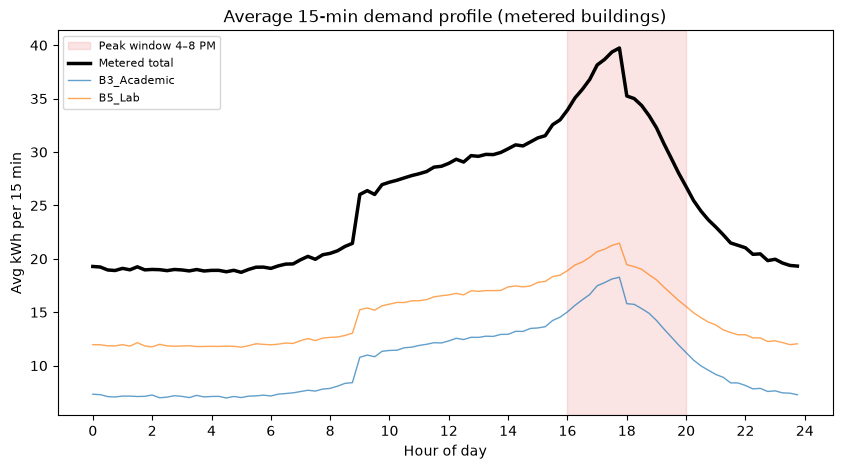

4–8 PM accounts for 23.0% of daily metered consumption


In [4]:
tod = interval["timestamp"].dt.hour + interval["timestamp"].dt.minute / 60
profile = interval.groupby([tod, "building"])["kWh_consumed"].mean().unstack()
metered_total = profile.sum(axis=1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.axvspan(16, 20, color="tab:red", alpha=0.12, label="Peak window 4–8 PM")
ax.plot(metered_total.index, metered_total.values, color="black", lw=2.5, label="Metered total")
for b in profile.columns:
    ax.plot(profile.index, profile[b], lw=1, alpha=0.7, label=b)
ax.set_xticks(range(0, 25, 2))
ax.set_xlabel("Hour of day")
ax.set_ylabel("Avg kWh per 15 min")
ax.set_title("Average 15-min demand profile (metered buildings)")
ax.legend(fontsize=8)
plt.show()

peak_share = metered_total.loc[16:19.75].sum() / metered_total.sum()  # intervals 4:00–7:45 PM
print(f"4–8 PM accounts for {peak_share:.1%} of daily metered consumption")